# Penghubung E1–E2: perubahan peta dan relevansi ranking terhadap RMS-matched

**Analisis tambahan eksploratori**, dirancang setelah hasil E1/E2 dan kontrol
amplitudo diketahui. Identitas: `E1_E2_RMS_ARTIFACT_BRIDGE_V1`; tanggal desain
2026-10-14. Ini terpisah dari rencana E3 perturbasi input sebelumnya; status dan
tanggal protokol lama tidak diubah.

Pertanyaan: **Pada pasangan seed dan rekaman yang sama, apakah perubahan
attention map berhubungan dengan perubahan keuntungan ranking attention
terhadap kontrol acak yang RMS dan geometrinya sebanding?**

Notebook hanya membaca artefak tersimpan. Tidak memuat model untuk inference,
tidak membuat intervensi, tidak melakukan training, dan tidak menyunting
manuskrip. Checkpoint dibaca sebagai byte untuk verifikasi SHA256 dan metadata.
Tidak memerlukan CUDA. E1 yang digunakan adalah E1 baru dari notebook 16 pada
checkpoint E2 yang sama, bukan E1 lama notebook 15. E1/E2 lama tetap pembanding.

## Menjalankan

1. Buka `notebooks/18_e1_e2_rms_bridge.ipynb`; pilih kernel **Skripsi (.venv)**.
2. **Restart Kernel → Run All**. Sel pertama mengunci dua run sumber yang sudah
   lengkap. Jangan mengganti ke folder "terbaru" secara otomatis.
3. Jika verifikasi gagal, baca `alignment_checks.csv` dan exception. Jangan
   memperlebar toleransi, menghapus seed, mengisi matching yang gagal, atau
   menjalankan ulang intervensi sebagai fallback.
4. Hasil baru masuk ke `results/e1_e2_rms_bridge/<run_id>/` dan
   `figures/e1_e2_rms_bridge/<run_id>/`. Setiap Run All membuat folder baru.
   Bootstrapping 5.000 kali memakai CPU; itu Anda jalankan sendiri.

Pembangun: `python scripts/build_nb_18.py`. Pembangun hanya menghasilkan
notebook tanpa eksekusi. Semua definisi analisis ada di sel notebook ini.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from hashlib import sha256
from importlib.metadata import version
from itertools import combinations
import json
import pickle
import sys
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import expit
from scipy.spatial.distance import jensenshannon
from scipy.stats import rankdata
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'src/audit_e2.py').is_file())
BASELINE = ROOT/'results/e2/20261012T050124548170Z'
AMPLITUDE = ROOT/'results/e2_amplitude/20261014T024232464643Z'
NOTEBOOK = ROOT/'notebooks/18_e1_e2_rms_bridge.ipynb'
BUILDER = ROOT/'scripts/build_nb_18.py'
ANALYSIS_KIND = 'E1_E2_RMS_ARTIFACT_BRIDGE_V1'
DESIGN_DATE = '2026-10-14'
EXPECTED_EVALUATION = 'c4b1d743f22d6b9bbbc5b2a2a8fcd7d913ba2543108895f8e70de9b4c1b79823'
EXPECTED_CONTROL = '1d839c2be1e4cc601eeaffc85acc7e380265bf076940f2a62b76648bee9a8ac7'
N_BOOT, BOOT_SEED, CONFIDENCE = 5000, 1801, .95
MIN_CI_SUBJECTS = 10  # aturan pelaporan, bukan bukti power
DENOM_FLOORS = (1e-8, 1e-6, 1e-4)
PRIMARY_FLOOR = DENOM_FLOORS[0]
EPS_PROB = (.01, .02, .05)
EPS_LOGIT = (.1, .25, .5)
METRICS = ('abs_delta_logit', 'signed_margin_drop', 'predicted_class_prob_drop')
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = ROOT/'results/e1_e2_rms_bridge'/RUN_ID
FIG = ROOT/'figures/e1_e2_rms_bridge'/RUN_ID
OUT.mkdir(parents=True, exist_ok=False)
FIG.mkdir(parents=True, exist_ok=False)
run_manifest = dict(run_id=RUN_ID,analysis_kind=ANALYSIS_KIND,analysis_design_date=DESIGN_DATE,
    analysis_status='additional_exploratory_after_E1_E2_RMS_results_known',completion_status='initializing',
    old_preregistration_changed=False,training_performed=False,model_inference_performed=False,
    new_interventions_performed=False,original_E3_input_perturbation_plan_executed=False,
    baseline_run=BASELINE.name,amplitude_run=AMPLITUDE.name)
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
print('Analisis eksploratori terpisah:', ANALYSIS_KIND)
print('Sumber:', BASELINE.name, AMPLITUDE.name)
print('Output:', OUT)

Analisis eksploratori terpisah: E1_E2_RMS_ARTIFACT_BRIDGE_V1
Sumber: 20261012T050124548170Z 20261014T024232464643Z
Output: /home/agribychaniago/Python Projects/Skripsi/results/e1_e2_rms_bridge/20261014T041914953496Z


## Estimator dan batas interpretasi

Pada setiap seed, rekaman, dan masker:

- (T_s): deletion AOPC attention-top untuk |Δlogit|.
- (R_s): AOPC kontrol RMS-matched, repeat dirata-ratakan dalam background,
  lalu background diberi bobot sama, sesuai notebook 17.
- (G_s=T_s-R_s): keuntungan absolut attention. Hubungan utama ialah
  **JSD divergence basis 2** versus **|G_b−G_a|** pada irisan dua seed yang
  matching-nya lengkap di semua empat budget dan semua background. AOPC
  mengintegrasikan titik tersimpan plus anchor nol, dibagi budget aktual terakhir.
  Ini normalisasi panjang kurva, **bukan** normalisasi skala logit.
- Sensitivitas skala: (H_s=(T_s-R_s)/(T_s+R_s)), dalam [−1,1], hanya bila
  (T_s+R_s>10^{-8}). Bandingkan JSD dengan |H_b−H_a|. H invariant terhadap
  perkalian positif semua logit/intervensi dalam seed; juga invariant terhadap
  translasi logit karena berbasis selisih. H tidak mengkalibrasi probabilitas,
  mengabaikan besar pengaruh absolut, dan dapat sensitif dekat respons nol.
  Tidak membagi dengan logit asli yang dapat mendekati nol. Floor 10⁻⁶ dan
  10⁻⁴ menjadi sensitivitas; kasus gagal tidak diberi epsilon dalam rasio.
  Nilai H invariant skala; kelayakan yang ditentukan floor absolut tidak.

Raw dan normalized dibandingkan **pada support normalized-valid yang sama**,
di samping estimasi raw primer pada seluruh support matching. Perbedaan skala
logit ditinjau dari IQR logit asli dan AOPC per subjek/seed. Skala tidak disamakan
melalui temperature fitting, label, atau masked-output tuning.

Asosiasi primer adalah weighted Spearman pada pasangan, dengan bobot
**subjek sama → rekaman eligible sama → pasangan seed eligible sama**. Ini
asosiasi gabungan variasi dalam dan antar-subjek, bukan efek kausal dalam subjek.
Weighted Pearson setelah centering dalam subjek menjadi sensitivitas untuk
memisahkan variasi antar-subjek. Tidak memberi p-value yang menganggap pasangan
seed independen. Bootstrap meresampling seluruh subjek, distratifikasi HC/PD,
mempertahankan semua rekaman/pasangan dalam cluster. Ranking tertimbang dihitung
ulang setiap draw. Draw subjek sama untuk seluruh model, masker, dan estimand.

CI 95% percentile **bersyarat pada checkpoint, split, seed, donor library,
kontrol, dan hasil matching yang sudah tersimpan**; tidak mencakup training
ulang, seed populasi, atau ketidakpastian pencarian matching baru. Subjek tanpa
pasangan eligible tetap di pool bootstrap. CI disembunyikan bila <10 subjek
eligible atau <95% draw menghasilkan estimator finite; bukan jaminan power.
CI eksploratori tidak dikoreksi untuk multiplicity; jangan memilih masker,
budget, ukuran peta, atau threshold berdasarkan hasil yang paling mendukung.
Untuk sensitivitas centering, aturan ≥10 berlaku pada subjek dengan variasi
dalam-subjek pada kedua variabel, bukan sekadar jumlah subjek hadir. CI mean
|perubahan| yang positif bukan uji penurunan kualitas.

**Peta berubah ≠ relevansi berubah ≠ kualitas turun.** |ΔG|/ |ΔH| mengukur
perbedaan keuntungan ranking, bukan penurunan: orientasi seed a<b bukan waktu.
G/H negatif tidak sendirian membuktikan attention tidak faithful. Kontrol
bersyarat pada dose dan geometri per seed; dose/geometry attention sendiri
dapat berbeda antar-seed. Masker tetap dapat membuat input di luar distribusi.
Fungsi prediksi model juga berubah antar-seed. Analisis ini tidak mengisolasi
efek mengganti ranking sambil menahan satu model tetap; itu memerlukan pengujian
lain dan tidak dilakukan di notebook ini.
Signed margin/probability drop dilaporkan terpisah; class-probability drop
mengacu kelas prediksi masing-masing seed, sehingga lintas kelas hanya
dibandingkan sebagai nilai numerik, bukan dukungan bagi target kelas yang sama.

In [2]:
class AlignmentError(ValueError):
    pass

checks = []
tracked = {}

def file_hash(path):
    h = sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

def digest(value):
    return sha256(json.dumps(value, sort_keys=True, separators=(',', ':')).encode()).hexdigest()

def source_digest(path):
    doc = json.loads(Path(path).read_text(encoding='utf-8'))
    sources = [dict(type=c['cell_type'],source=''.join(c.get('source',[]))) for c in doc['cells']]
    # Same content-only algorithm as notebook 17: include prose; exclude outputs.
    return sha256(json.dumps(sources,sort_keys=True,ensure_ascii=False).encode()).hexdigest()

def check(condition, name, detail=''):
    passed = bool(condition)
    checks.append(dict(check=name, passed=passed, detail=str(detail)))
    if not passed or len(checks)%1000==0:
        pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv', index=False)
    if not passed:
        run_manifest.update(completion_status='alignment_failed',failed_check=name,failed_detail=str(detail))
        (OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
        raise AlignmentError(name + ': ' + str(detail))

def track(path, expected=None):
    path = Path(path).resolve()
    check(path.is_file(), 'file exists', path.relative_to(ROOT))
    actual = file_hash(path)
    if expected is not None:
        check(actual==expected, 'SHA256', path.relative_to(ROOT))
    if path in tracked:
        check(tracked[path]==actual, 'source stable during preflight', path.relative_to(ROOT))
    tracked[path] = actual
    return actual

def read_csv(path):
    track(path)
    return pd.read_csv(path)

def bool_column(frame, name):
    text = frame[name].astype(str).str.lower()
    check(text.isin(['true','false']).all(), 'strict boolean '+name)
    frame[name] = text.eq('true')

def finite_close(a, b, name, atol=1e-8, rtol=1e-8):
    a, b = np.asarray(a, float), np.asarray(b, float)
    check(a.shape==b.shape and np.allclose(a, b, atol=atol, rtol=rtol, equal_nan=True), name)

def unique(frame, keys, name):
    check(not frame.duplicated(keys).any(), 'unique '+name, ','.join(keys))

def mask_hash(selected):
    return sha256(np.asarray(selected, dtype='<i8').tobytes()).hexdigest()

def keyed_seed(seed, *keys):
    # Exact baseline algorithm, including string conversion and JSON separators.
    key = json.dumps([int(seed), *map(str,keys)],separators=(',', ':'))
    return int.from_bytes(sha256(key.encode()).digest()[:8], 'little')

def attention_measures(a, b, fraction):
    a, b = np.asarray(a, float), np.asarray(b, float)
    check(a.shape==b.shape and a.ndim==1 and len(a)>=3, 'same alpha grid')
    check(np.isfinite(a).all() and np.isfinite(b).all() and (a>=0).all() and (b>=0).all(), 'alpha values')
    check(np.isclose(a.sum(),1,atol=1e-4,rtol=0) and np.isclose(b.sum(),1,atol=1e-4,rtol=0), 'alpha mass')
    a, b = a/a.sum(), b/b.sum()
    ra, rb = rankdata(a), rankdata(b)
    ra, rb = ra-ra.mean(), rb-rb.mean()
    den = np.linalg.norm(ra)*np.linalg.norm(rb)
    rho = float(np.clip(ra@rb/den, -1, 1)) if den>0 else np.nan
    def top_weights(alpha):
        k = max(1, int(np.ceil(len(alpha)*fraction)))
        cutoff = np.partition(alpha, len(alpha)-k)[len(alpha)-k]
        above, boundary = alpha>cutoff, alpha==cutoff
        out = above.astype(float)
        out[boundary] = (k-above.sum())/boundary.sum()
        return out
    wa, wb = top_weights(a), top_weights(b)
    return dict(js_divergence=float(np.clip(jensenshannon(a,b,base=2)**2,0,1)),
                rank_disagreement=(1-rho)/2 if np.isfinite(rho) else np.nan,
                top_jaccard_fractional=float(np.minimum(wa,wb).sum()/np.maximum(wa,wb).sum()))

In [3]:
track(BASELINE/'analysis_manifest.json')
track(AMPLITUDE/'analysis_manifest.json')
baseline_manifest = json.loads((BASELINE/'analysis_manifest.json').read_text())
amplitude_manifest = json.loads((AMPLITUDE/'analysis_manifest.json').read_text())
recipe = baseline_manifest['evaluation_spec']
control_spec = amplitude_manifest['control_spec']
check(baseline_manifest['completion_status']=='complete'
      and amplitude_manifest['completion_status']=='complete', 'both source runs complete')
check(baseline_manifest['evaluation_id']==EXPECTED_EVALUATION
      and amplitude_manifest['control_id']==EXPECTED_CONTROL, 'pinned evaluation/control IDs')
check(control_spec['baseline_evaluation_id']==EXPECTED_EVALUATION
      and control_spec['baseline_run_id']==BASELINE.name
      and control_spec['recipe']==recipe, 'same evaluation recipe')
check(amplitude_manifest['training_performed'] is False, 'amplitude reused checkpoints')
check(recipe['jsd']==dict(kind='divergence',log_base=2,
                         input='nonnegative alpha normalized to sum 1',range=[0,1]), 'JSD definition')
ARMS, SEEDS = tuple(recipe['arms']), tuple(recipe['seeds'])
FRACTIONS, PATCH, FS = tuple(recipe['fractions']), int(recipe['patch']), float(recipe['fs'])
MASKERS = ('train_median','train_donor')
check(ARMS==('gru','mamba2') and SEEDS==(0,1,2) and FRACTIONS==(.05,.1,.2,.3)
      and PATCH==7 and FS==100., 'expected arms/seeds/grid/budgets')
check(control_spec['matching']==dict(relative_tolerance=.05,absolute_tolerance=1e-8,
      max_candidates_per_budget=4096,candidate_batch=128,seed=1700,
      geometry='exact multiset of linear contiguous run lengths',identity_excluded=True,
      overlap_allowed=True,nested=False,quota=20,donor_quota_per_background=4,no_fallback=True),
      'RMS matching recipe unchanged')
for folder in (BASELINE, AMPLITUDE):
    inventory = read_csv(folder/'input_inventory.csv')
    bool_column(inventory, 'unchanged')
    check(inventory.unchanged.all(), 'source inventory marked unchanged', folder.name)
    for entry in inventory.itertuples(index=False):
        check(entry.sha256_before==entry.sha256_after, 'source before/after hashes', entry.path)
        track(ROOT/entry.path, entry.sha256_after)
for path, expected in control_spec['baseline_hashes'].items():
    track(ROOT/path, expected)
check(source_digest(ROOT/amplitude_manifest['scientific_source'])
      ==amplitude_manifest['notebook_source_sha256'], 'amplitude scientific notebook source')
track(BUILDER)
SOURCE_DIGEST = source_digest(NOTEBOOK)
records = read_csv(BASELINE/'record_manifest.csv')
models = read_csv(BASELINE/'model_inventory.csv')
amp_models = read_csv(AMPLITUDE/'model_inventory.csv')
e1 = read_csv(BASELINE/'e1_pairs_new.csv')
points = read_csv(AMPLITUDE/'point_contrasts.csv')
contrasts = read_csv(AMPLITUDE/'record_contrasts.csv')
diagnostics = read_csv(AMPLITUDE/'matching_diagnostics.csv')
baseline_curve = read_csv(BASELINE/'e2_curve_mean.csv')
for frame, column in ((contrasts,'matched_curve_complete'),(points,'matched_budget_complete'),
                       (diagnostics,'complete'),(amp_models,'training_performed')):
    bool_column(frame,column)
check(not amp_models.training_performed.any(), 'no training in amplitude inventory')
unique(records,['idx'],'record index')
unique(records,['record_id'],'record ID')
check(np.array_equal(records.idx.to_numpy(),np.arange(len(records))), 'record index positional mapping')
check((records.cohort=='newhandpd').all() and (records.fs==FS).all()
      and (records.patch_size==PATCH).all(), 'cohort temporal acquisition grid')
finite_close(records.patch_seconds, np.full(len(records),PATCH/FS), 'patch duration')
check(np.array_equal(records.n_patches, records.n_samples//PATCH)
      and np.array_equal(records.tail_samples,records.n_samples%PATCH), 'full patches and unmasked tail')
subjects = records[['subject','label']].drop_duplicates().sort_values('subject').reset_index(drop=True)
unique(subjects,['subject'],'subject labels')
check(set(subjects.label)=={0,1}, 'HC/PD label encoding')
MODEL_KEYS = ['architecture','seed','fold','model_id']
unique(models,['model_id'],'model ID')
unique(models,['architecture','seed','fold'],'architecture/seed/fold')
unique(amp_models,['model_id'],'amplitude model ID')
check(set(zip(models.architecture,models.seed,models.fold))
      =={(a,s,f) for a in ARMS for s in SEEDS for f in range(5)}, 'complete model inventory')
common_cols = MODEL_KEYS+['checkpoint','checkpoint_sha256']
check(models[common_cols].sort_values('model_id').reset_index(drop=True).equals(
      amp_models[common_cols].sort_values('model_id').reset_index(drop=True)), 'checkpoint identity shared E1/E2')
specs = {}
for row in models.itertuples(index=False):
    checkpoint = ROOT/row.checkpoint
    track(checkpoint,row.checkpoint_sha256)
    meta_path = checkpoint.parent/'metadata.json'
    track(meta_path)
    meta = json.loads(meta_path.read_text())
    spec = meta['spec']
    check(meta['model_id']==row.model_id and digest(spec)==row.model_id
          and meta['checkpoint_sha256']==row.checkpoint_sha256, 'checkpoint metadata digest', row.model_id)
    check((spec['architecture'],spec['seed'],spec['fold'])==(row.architecture,row.seed,row.fold)
          and spec['cohort']==recipe['cohort'] and spec['cache_sha256']==recipe['cache_sha256']
          and spec['model_config']==recipe['model_config'] and spec['training_config']==recipe['training_config'],
          'checkpoint training configuration', row.model_id)
    train,test = spec['split']['train_indices'],spec['split']['test_indices']
    check(len(train)==len(set(train)) and len(test)==len(set(test))
          and not set(train)&set(test) and set(train)|set(test)==set(records.idx), 'split indices', row.model_id)
    check(not set(records.subject.iloc[train])&set(records.subject.iloc[test])
          and (records.fold_actual.iloc[test]==row.fold).all()
          and records.record_id.iloc[train].tolist()==spec['split']['train_record_ids']
          and records.record_id.iloc[test].tolist()==spec['split']['test_record_ids'], 'subject-disjoint split', row.model_id)
    for source, checksum in spec['sources'].items():
        track(ROOT/source,checksum)
    specs[row.model_id] = spec
for fold in range(5):
    splits = [spec['split'] for spec in specs.values() if spec['fold']==fold]
    check(all(split==splits[0] for split in splits), 'identical fold split across architectures and seeds', fold)

In [4]:
track(BASELINE/'joint_oof_maps.pkl')
# Trusted local artifact produced by notebook 16; no raw dataset/model loading.
runs = pickle.loads((BASELINE/'joint_oof_maps.pkl').read_bytes())
maps = {}
seen_runs = set()
for run in runs:
    run_key = (run['arsitektur'],int(run['seed']))
    check(run_key not in seen_runs, 'unique OOF run', run_key)
    seen_runs.add(run_key)
    check(run['config']=={**recipe['model_config'],**recipe['training_config']}, 'OOF run configuration')
    check(np.asarray(run['logit_oof']).shape==(len(records),)
          and np.isfinite(run['logit_oof']).all()
          and np.asarray(run['fold_oof']).shape==(len(records),), 'finite complete OOF vectors')
    for p in run['peta']:
        key = (p['model_id'],int(p['idx']))
        check(key not in maps and key[0] in specs, 'unique known checkpoint/record map', key)
        rec = records.iloc[key[1]]
        spec = specs[key[0]]
        check((p['arsitektur'],p['seed'])==run_key
              and (p['arsitektur'],p['seed'],p['fold'])==(spec['architecture'],spec['seed'],spec['fold'])
              and str(p['subjek'])==rec.subject and int(p['label'])==int(rec.label)
              and int(p['tugas'])==int(rec.task) and int(p['fold'])==int(rec.fold_actual)
              and int(p['patch'])==PATCH and float(p['fs'])==FS
              and np.asarray(p['alpha']).shape==(int(rec.n_patches),), 'OOF map identity/grid', key)
        finite_close([p['logit']],[run['logit_oof'][key[1]]], 'OOF logit/map same entry')
        check(int(run['fold_oof'][key[1]])==int(rec.fold_actual), 'OOF fold identity')
        maps[key] = p
check(seen_runs=={(a,s) for a in ARMS for s in SEEDS}, 'OOF runs complete')
check(len(maps)==len(records)*len(ARMS)*len(SEEDS), 'OOF maps complete')
unique(e1,['architecture','idx','seed_a','seed_b'],'E1 pairs')
expected_pairs = {(a,int(i),sa,sb) for a in ARMS for i in records.idx for sa,sb in combinations(SEEDS,2)}
check(set(zip(e1.architecture,e1.idx,e1.seed_a,e1.seed_b))==expected_pairs, 'all expected E1 seed pairs')
for p in e1.itertuples(index=False):
    rec = records.iloc[p.idx]
    check(p.cohort=='newhandpd' and p.subject==rec.subject and p.record_id==rec.record_id
          and p.label==rec.label and p.task==rec.task and p.fold_actual==rec.fold_actual
          and p.n_patches==rec.n_patches and p.patch_seconds==rec.patch_seconds
          and p.top_fraction==.1, 'E1 record/subject/fold/grid', p.record_id)
    ma,mb = maps[(p.e1_model_id_a,p.idx)],maps[(p.e1_model_id_b,p.idx)]
    check((ma['arsitektur'],ma['seed'],mb['arsitektur'],mb['seed'])
          ==(p.architecture,p.seed_a,p.architecture,p.seed_b), 'E1 pair checkpoint/seed identity')
    finite_close([p.logit_a,p.logit_b],[ma['logit'],mb['logit']], 'E1 original logits')
    finite_close([p.probability_a,p.probability_b],expit([ma['logit'],mb['logit']]), 'E1 probabilities')
    finite_close([p.abs_delta_prob,p.abs_delta_logit,p.class_agreement],
                 [abs(p.probability_b-p.probability_a),abs(p.logit_b-p.logit_a),
                  float((p.logit_a>=0)==(p.logit_b>=0))], 'E1 output changes')
    fresh = attention_measures(ma['alpha'],mb['alpha'],p.top_fraction)
    finite_close([getattr(p,k) for k in fresh],list(fresh.values()), 'saved E1 map metrics')

def verify_identity(frame, name):
    for row in frame[MODEL_KEYS+['idx','subject','label','record_id']].drop_duplicates().itertuples(index=False):
        check(row.model_id in specs and row.idx in records.idx.values, name+' known identity')
        spec,rec = specs[row.model_id],records.iloc[row.idx]
        check((row.architecture,row.seed,row.fold)==(spec['architecture'],spec['seed'],spec['fold'])
              and row.subject==rec.subject and row.label==rec.label and row.record_id==rec.record_id
              and row.fold==rec.fold_actual and row.idx in spec['split']['test_indices'], name+' OOF identity')
    check(set(frame.masker)==set(MASKERS), name+' maskers')

# The legacy mean-curve table predates record_id. Resolve it through the
# authoritative manifest, checking subject, label and fold alongside idx.
baseline_required = MODEL_KEYS+['idx','subject','label','masker','ranking',
                               'requested_fraction','actual_fraction',*METRICS]
check(set(baseline_required).issubset(baseline_curve.columns), 'baseline mean-curve schema',
      sorted(set(baseline_required)-set(baseline_curve.columns)))
if 'record_id' not in baseline_curve.columns:
    identity_keys = ['idx','subject','label','fold']
    identity_lookup = records[['idx','subject','label','fold_actual','record_id']].rename(
                      columns={'fold_actual':'fold'})
    n_baseline_rows = len(baseline_curve)
    baseline_curve = baseline_curve.merge(identity_lookup,on=identity_keys,how='left',
                        validate='many_to_one',indicator='_record_alignment')
    unmatched = baseline_curve.loc[baseline_curve['_record_alignment']!='both',identity_keys]
    check(len(baseline_curve)==n_baseline_rows and unmatched.empty,
          'baseline record IDs resolved against manifest',unmatched.head(5).to_dict('records'))
    baseline_curve = baseline_curve.drop(columns='_record_alignment')
verify_identity(baseline_curve,'baseline mean curves')
unique(baseline_curve,['model_id','idx','masker','ranking','requested_fraction'],'baseline mean curves')

for name,frame in (('record contrasts',contrasts),('point contrasts',points),('matching diagnostics',diagnostics)):
    verify_identity(frame,name)
RECORD_KEYS = MODEL_KEYS+['idx','subject','label','record_id','masker']
POINT_KEYS = RECORD_KEYS+['requested_fraction','actual_fraction']
unique(contrasts,['model_id','idx','masker'],'record contrasts')
unique(points,['model_id','idx','masker','requested_fraction'],'point contrasts')
unique(diagnostics,['model_id','idx','masker','requested_fraction','donor_repeat'],'matching targets')
check(set(zip(contrasts.model_id,contrasts.idx,contrasts.masker))
      =={(mid,idx,masker) for mid,idx in maps for masker in MASKERS}, 'complete E2 record coverage')
selected_masks = {}
for row in diagnostics.itertuples(index=False):
    rec = records.iloc[row.idx]
    w = int(rec.n_patches)
    k = max(1,int(np.ceil(w*row.requested_fraction)))
    check(row.requested_fraction in FRACTIONS and row.n_patches==w and row.n_masked==k
          and np.isclose(row.actual_fraction,k/w,atol=1e-12,rtol=0), 'matching budget/grid')
    n_required = 20 if row.masker=='train_median' else 4
    check(row.n_required==n_required and 0<=row.n_matches_found<=n_required
          and bool(row.complete)==(row.n_matches_found==n_required), 'matching quota/completeness')
    check(np.isfinite(row.target_rms) and row.target_rms>=0, 'target RMS finite')
    alpha = np.asarray(maps[(row.model_id,row.idx)]['alpha'])
    tie = np.random.default_rng(keyed_seed(recipe['intervention_seed'],row.record_id,'ties')).random(w)
    selected = np.sort(np.lexsort((tie,-alpha))[:k])
    selected_masks[(row.model_id,int(row.idx),float(row.requested_fraction))] = selected
    check(mask_hash(selected)==row.target_mask_sha256, 'attention target mask hash')
    cuts = np.flatnonzero(np.diff(selected)>1)+1
    lengths = sorted(map(len,np.split(selected,cuts)))
    check(json.loads(row.target_run_lengths)==lengths, 'attention patch-run geometry')

diag_rows = []
for key,group in diagnostics.groupby(POINT_KEYS,sort=True):
    row = dict(zip(POINT_KEYS,key))
    expected_bg = {0} if row['masker']=='train_median' else set(range(recipe['donor_repeats']))
    check(set(group.donor_repeat)==expected_bg and len(group)==len(expected_bg), 'all background identities')
    row['verified_complete'] = bool(group.complete.all())
    row['verified_backgrounds'] = len(group)
    row['target_rms_mean'] = float(group.target_rms.mean())
    row['n_masked'] = int(group.n_masked.iloc[0])
    row['n_patches_verified'] = int(group.n_patches.iloc[0])
    row['target_mask_sha256'] = group.target_mask_sha256.iloc[0]
    check(group.target_mask_sha256.nunique()==1, 'same attention target across donor backgrounds')
    for metric in METRICS:
        row['verified_top_'+metric] = float(group['top_'+metric].mean())
    diag_rows.append(row)
diag_point = pd.DataFrame(diag_rows)
points = points.merge(diag_point,on=POINT_KEYS,how='outer',validate='one_to_one',indicator=True)
check((points['_merge']=='both').all(), 'point/diagnostic intersection is exact')
points = points.drop(columns='_merge')
check(np.array_equal(points.matched_budget_complete,points.verified_complete)
      and np.array_equal(points.n_backgrounds,points.verified_backgrounds), 'complete matching flags from all backgrounds')
old_top = baseline_curve[baseline_curve.ranking=='alpha_top'][POINT_KEYS+list(METRICS)].rename(
          columns={m:'baseline_top_'+m for m in METRICS})
points = points.merge(old_top,on=POINT_KEYS,how='left',validate='one_to_one')
for metric in METRICS:
    finite_close(points['top_'+metric],points['verified_top_'+metric], 'background-averaged top '+metric)
    check(np.isfinite(points['top_'+metric]).all(), 'finite attention outcomes '+metric)
    finite_close(points['top_'+metric],points['baseline_top_'+metric], 'baseline top unchanged '+metric)
    finite_close(points['paired_rms_'+metric],points['top_'+metric]-points['rms_'+metric], 'paired RMS contrast '+metric)
    check(np.isfinite(points.loc[points.matched_budget_complete,'rms_'+metric]).all(), 'complete RMS outcomes '+metric)
    check(points.loc[~points.matched_budget_complete,'rms_'+metric].isna().all(), 'incomplete RMS not imputed '+metric)
for key,group in points.groupby(RECORD_KEYS,sort=True):
    group = group.sort_values('requested_fraction')
    check(tuple(group.requested_fraction)==FRACTIONS, 'all four budgets for record')
    old = contrasts.loc[(contrasts.model_id==key[3])&(contrasts.idx==key[4])&(contrasts.masker==key[-1])]
    check(len(old)==1, 'one record contrast for point grid')
    old = old.iloc[0]
    check(bool(old.matched_curve_complete)==bool(group.matched_budget_complete.all()), 'full-curve completeness')
    grid = np.r_[0.,group.actual_fraction.to_numpy()]
    for metric in METRICS:
        for ranking in ('top','rms'):
            values = group[ranking+'_'+metric].to_numpy(float)
            aopc = float(np.trapezoid(np.r_[0.,values],grid)/grid[-1]) if np.isfinite(values).all() else np.nan
            finite_close([aopc],[old['aopc_'+ranking+'_'+metric]], 'saved AOPC '+ranking+' '+metric)
        finite_close([old['paired_rms_'+metric]],
                     [old['aopc_top_'+metric]-old['aopc_rms_'+metric]], 'record paired RMS '+metric)
check((contrasts.aopc_top_abs_delta_logit>=0).all()
      and (contrasts.loc[contrasts.matched_curve_complete,'aopc_rms_abs_delta_logit']>=0).all(), 'nonnegative absolute effects')
pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv',index=False)
run_manifest['completion_status'] = 'preflight_passed'
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
print('Preflight passed: source SHA, checkpoints, subjects, grids, targets, quotas, AOPC; no model inference.')

Preflight passed: source SHA, checkpoints, subjects, grids, targets, quotas, AOPC; no model inference.


### Verifikasi kontrol RMS tersimpan

Sel berikut membaca `controls_raw.csv`, memeriksa caliper RMS, geometri,
kuota tiap background, anchor/logit tersimpan, dan mean kontrol pada tabel point.
Ini pemeriksaan ulang artefak, bukan inference, replay model, atau intervensi
baru. Matching yang gagal tetap gagal; tidak mengambil kandidat "nearest".
Satu titik donor dapat memiliki background yang berhasil dan yang gagal.
Baris RMS background berhasil tetap sah sebagai artefak, tetapi titik tersebut
tidak dipakai bila seluruh background belum lengkap. `rms_background_support.csv`
mencatat pemisahan ini; rata-rata lintas-background untuk verifikasi hanya
dibentuk pada titik dengan matching lengkap, sesuai notebook 17.

In [5]:
track(AMPLITUDE/'controls_raw.csv')
raw_columns = MODEL_KEYS+['idx','subject','label','record_id','masker','donor_repeat',
    'requested_fraction','actual_fraction','n_masked','n_patches','target_mask_sha256',
    'target_run_lengths','target_rms','control','repeat','original_logit','perturbed_logit',
    'original_class','forward_batch_size','input_rms_change','run_lengths',
    'geometry_matches_attention','mask_sha256','unmasked_logit_before','unmasked_logit_after',
    *METRICS]
rms_raw = pd.read_csv(AMPLITUDE/'controls_raw.csv',usecols=raw_columns)
rms_raw = rms_raw.loc[rms_raw.control=='rms_matched_random'].copy()
bool_column(rms_raw,'geometry_matches_attention')
BG_KEYS = POINT_KEYS+['donor_repeat']
unique(rms_raw,BG_KEYS+['repeat'],'RMS background/repeat')
target_columns = BG_KEYS+['n_required','complete','n_masked','n_patches',
                         'target_mask_sha256','target_run_lengths','target_rms']
verify_raw = rms_raw.merge(diagnostics[target_columns],on=BG_KEYS,how='left',validate='many_to_one',
                           suffixes=('','_diag'),indicator=True)
check((verify_raw['_merge']=='both').all() and verify_raw.complete.all(), 'RMS rows have complete targets')
for column in ('n_masked','n_patches','target_mask_sha256','target_run_lengths'):
    check(np.array_equal(verify_raw[column],verify_raw[column+'_diag']), 'raw RMS target identity '+column)
finite_close(verify_raw.target_rms,verify_raw.target_rms_diag,'raw RMS target dose')
check(verify_raw.geometry_matches_attention.all(), 'RMS geometry matched')
check((verify_raw.mask_sha256!=verify_raw.target_mask_sha256).all(), 'RMS identity mask excluded')
check((verify_raw.forward_batch_size==recipe['forward_batch_size']).all(), 'same stored forward batch recipe')
caliper = control_spec['matching']['absolute_tolerance'] + control_spec['matching']['relative_tolerance']*verify_raw.target_rms
check(np.isfinite(verify_raw.input_rms_change).all()
      and (verify_raw.input_rms_change>=0).all()
      and (abs(verify_raw.input_rms_change-verify_raw.target_rms)<=caliper).all(), 'RMS input caliper satisfied')
check(all(json.loads(a)==json.loads(b) for a,b in zip(verify_raw.run_lengths,verify_raw.target_run_lengths)),
      'RMS exact run-length multiset')
original_lookup = pd.DataFrame([dict(model_id=mid,idx=idx,saved_logit=float(p['logit']))
                               for (mid,idx),p in maps.items()])
verify_raw = verify_raw.merge(original_lookup,on=['model_id','idx'],how='left',validate='many_to_one')
check(np.isfinite(verify_raw.perturbed_logit).all(), 'stored RMS outputs finite')
finite_close(verify_raw.original_logit,verify_raw.saved_logit,'RMS original logits vs E1',atol=1e-4,rtol=1e-4)
for phase in ('before','after'):
    finite_close(verify_raw['unmasked_logit_'+phase],verify_raw.original_logit,
                 'stored RMS unmasked anchor '+phase,atol=1e-4,rtol=1e-4)
check(np.array_equal(verify_raw.original_class,verify_raw.original_logit>=0), 'RMS original predicted class')
sign = 2*verify_raw.original_class.to_numpy(float)-1
finite_close(verify_raw.abs_delta_logit,abs(verify_raw.original_logit-verify_raw.perturbed_logit),'stored RMS absolute effects')
finite_close(verify_raw.signed_margin_drop,sign*(verify_raw.original_logit-verify_raw.perturbed_logit),'stored RMS signed effects')
finite_close(verify_raw.predicted_class_prob_drop,
             expit(sign*verify_raw.original_logit)-expit(sign*verify_raw.perturbed_logit),'stored RMS probability effects')
quota = diagnostics.loc[diagnostics.complete,BG_KEYS+['n_required']].merge(
    rms_raw.groupby(BG_KEYS).size().rename('n_observed').reset_index(),on=BG_KEYS,
    how='outer',validate='one_to_one',indicator=True)
check((quota['_merge']=='both').all() and np.array_equal(quota.n_required,quota.n_observed), 'complete RMS repeat quotas')
rms_background_mean = rms_raw.groupby(BG_KEYS)[list(METRICS)].mean().reset_index()
# Successful backgrounds can exist at an incomplete donor point. Bind every
# stored background to its point, then retain complete points before averaging;
# never treat a partial donor library as a complete point or reweight it.
rms_background_mean = rms_background_mean.merge(
    points[POINT_KEYS+['matched_budget_complete','n_backgrounds']],on=POINT_KEYS,
    how='left',validate='many_to_one',indicator='_point_membership')
unknown_backgrounds = rms_background_mean.loc[
    rms_background_mean['_point_membership']!='both',BG_KEYS]
check(unknown_backgrounds.empty, 'stored RMS backgrounds belong to known points',
      unknown_backgrounds.head(5).to_dict('records'))
rms_background_mean = rms_background_mean.drop(columns='_point_membership')
rms_background_mean[BG_KEYS+['matched_budget_complete','n_backgrounds']].to_csv(
    OUT/'rms_background_support.csv',index=False)
rms_background_mean = rms_background_mean.loc[rms_background_mean.matched_budget_complete].copy()
complete_background_counts = rms_background_mean.groupby(POINT_KEYS).size().rename(
    'verified_n_backgrounds').reset_index()
complete_background_counts = points.loc[points.matched_budget_complete,POINT_KEYS+['n_backgrounds']].merge(
    complete_background_counts,on=POINT_KEYS,how='outer',validate='one_to_one',indicator=True)
missing_backgrounds = complete_background_counts.loc[
    (complete_background_counts['_merge']!='both')
    |(complete_background_counts.n_backgrounds!=complete_background_counts.verified_n_backgrounds)]
check(missing_backgrounds.empty, 'complete points retain every RMS background',
      missing_backgrounds.head(5).to_dict('records'))
rms_point_mean = rms_background_mean.groupby(POINT_KEYS)[list(METRICS)].mean().reset_index()
rms_point_mean = rms_point_mean.rename(columns={m:'verified_rms_'+m for m in METRICS})
point_replay = points.loc[points.matched_budget_complete].merge(rms_point_mean,on=POINT_KEYS,
                                  how='outer',validate='one_to_one',indicator=True)
unmatched_points = point_replay.loc[point_replay['_merge']!='both',POINT_KEYS+['_merge']]
check(unmatched_points.empty, 'all complete point RMS aggregates',unmatched_points.head(5).to_dict('records'))
for metric in METRICS:
    finite_close(point_replay['rms_'+metric],point_replay['verified_rms_'+metric], 'RMS repeated-background aggregate '+metric)
pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv',index=False)
del rms_raw,verify_raw,rms_background_mean,rms_point_mean,point_replay
print('Stored RMS control balance, quotas, original outputs and point aggregates verified.')

Stored RMS control balance, quotas, original outputs and point aggregates verified.


## Support pasangan, ukuran perubahan, dan sensitivitas

Semua pasangan E1 tetap dalam tabel audit. Eligible berarti **kedua seed**
matching lengkap, bukan harus ketiga seed lengkap. Seed ketiga tidak diperlukan
untuk pasangan (a,b). Kegagalan salah satu background/budget mengecualikan
pasangan dari AOPC primer tanpa imputasi. Analisis tiap budget dilaporkan sebagai
sensitivitas dengan irisan kedua seed pada budget tersebut; support-nya dapat
berbeda dari full curve dan tidak boleh dianggap replikasi independen.

Subset output stabil adalah sensitivitas, bukan definisi primer: kelas sama
dan |Δp|≤{.01,.02,.05}, baik tanpa batas logit maupun dengan |Δz|≤{.1,.25,.5}.
Kriteria lama |Δp|≤.02, |Δz|≤.1 dipertahankan sebagai `stable_p0.02_z0.1`.
Batas logit absolut sendiri sensitif terhadap skala; probability-only ditampilkan
agar perubahan skala tidak otomatis menentukan siapa yang disebut stabil.
Coverage sebelum/sesudah matching dan setelah floor selalu dilaporkan. Seleksi
subset ini dapat mengubah populasi/asosiasi; bukan identifikasi sebab-akibat.

In [6]:
def pair_table(seed_table, *, level, value_prefix, complete_column):
    data = e1.copy().rename(columns={'e1_model_id_a':'model_id_a','e1_model_id_b':'model_id_b',
                                    'fold_actual':'fold'})
    data = data.loc[data.index.repeat(len(MASKERS))].reset_index(drop=True)
    data['masker'] = np.tile(MASKERS,len(e1))
    if level=='budget':
        data = data.loc[data.index.repeat(len(FRACTIONS))].reset_index(drop=True)
        data['requested_fraction'] = np.tile(FRACTIONS,len(e1)*len(MASKERS))
    join = ['architecture','idx','subject','label','record_id','fold','masker']
    if level=='budget':
        join += ['requested_fraction']
    include = join+['model_id','seed',complete_column]
    if level=='budget':
        include += ['actual_fraction','n_masked','n_patches_verified','target_rms_mean','target_mask_sha256']
    for metric in METRICS:
        include += [value_prefix+'top_'+metric,value_prefix+'rms_'+metric,'paired_rms_'+metric]
    for side in ('a','b'):
        rename = {c:c+'_'+side for c in include if c not in join}
        right = seed_table[include].rename(columns=rename)
        on = join+['model_id_'+side,'seed_'+side]
        data = data.merge(right,on=on,how='left',validate='many_to_one',indicator=True)
        check((data['_merge']=='both').all(), 'E1/E2 pair join '+level+' '+side)
        data = data.drop(columns='_merge')
    data['level'] = level
    data['level_id'] = 'aopc_all_budgets' if level=='aopc' else data.requested_fraction.map(lambda x:f'budget_{x:g}')
    data['pair_eligible'] = data[complete_column+'_a'] & data[complete_column+'_b']
    data['eligibility_reason'] = np.select(
        [data.pair_eligible,~data[complete_column+'_a']&~data[complete_column+'_b'],~data[complete_column+'_a']],
        ['both_complete','both_incomplete','seed_a_incomplete'],default='seed_b_incomplete')
    if level=='budget':
        finite_close(data.actual_fraction_a,data.actual_fraction_b,'paired same actual intervention fraction')
        check(np.array_equal(data.n_masked_a,data.n_masked_b)
              and np.array_equal(data.n_patches_verified_a,data.n_patches_verified_b)
              and np.array_equal(data.n_patches,data.n_patches_verified_a), 'paired same intervention grid/patch budget')
        data['abs_delta_target_rms'] = abs(data.target_rms_mean_b-data.target_rms_mean_a)
        mask_changes = []
        for row in data.itertuples(index=False):
            sa = selected_masks[(row.model_id_a,int(row.idx),float(row.requested_fraction))]
            sb = selected_masks[(row.model_id_b,int(row.idx),float(row.requested_fraction))]
            # Actual seeded integer top-k masks used by E2, not E1 fractional ties.
            mask_changes.append(1-len(np.intersect1d(sa,sb))/len(np.union1d(sa,sb)))
        data['used_top_mask_disagreement'] = mask_changes
        check(np.array_equal(data.used_top_mask_disagreement==0,
                             data.target_mask_sha256_a==data.target_mask_sha256_b), 'paired actual mask hashes/overlap')
    data['top_disagreement'] = 1-data.top_jaccard_fractional
    for metric in METRICS:
        for side in ('a','b'):
            data['gain_'+metric+'_'+side] = data['paired_rms_'+metric+'_'+side]
        data['signed_delta_gain_'+metric] = data['gain_'+metric+'_b']-data['gain_'+metric+'_a']
        data['abs_delta_gain_'+metric] = abs(data['signed_delta_gain_'+metric])
    for side in ('a','b'):
        t = data[value_prefix+'top_abs_delta_logit_'+side].to_numpy(float)
        r = data[value_prefix+'rms_abs_delta_logit_'+side].to_numpy(float)
        data['effect_sum_'+side] = t+r
        data['relative_gain_'+side] = np.divide(t-r,t+r,out=np.full(len(data),np.nan),
                                               where=np.asarray(t+r)>PRIMARY_FLOOR)
    data['normalization_eligible'] = data.pair_eligible & (data.effect_sum_a>PRIMARY_FLOOR) & (data.effect_sum_b>PRIMARY_FLOOR)
    data.loc[~data.normalization_eligible,['relative_gain_a','relative_gain_b']] = np.nan
    data['signed_delta_relative_gain'] = data.relative_gain_b-data.relative_gain_a
    data['abs_delta_relative_gain'] = abs(data.signed_delta_relative_gain)
    invalid = ~data.pair_eligible
    derived = [c for c in data if c.startswith(('gain_','signed_delta_gain_','abs_delta_gain_',
                                               'relative_gain_','signed_delta_relative','abs_delta_relative'))]
    data.loc[invalid,derived] = np.nan
    unique(data,['architecture','idx','seed_a','seed_b','masker','level_id'],'bridge pairs '+level)
    return data

pairs = pair_table(contrasts,level='aopc',value_prefix='aopc_',complete_column='matched_curve_complete')
budget_pairs = pair_table(points,level='budget',value_prefix='',complete_column='matched_budget_complete')
pairs.to_csv(OUT/'bridge_pairs_aopc.csv',index=False)
budget_pairs.to_csv(OUT/'bridge_pairs_budget.csv',index=False)

def scenario_gate(frame, eps_prob=None, eps_logit=None, same_class=False):
    gate = np.ones(len(frame),bool)
    if eps_prob is not None:
        gate &= frame.abs_delta_prob.to_numpy()<=eps_prob
    if eps_logit is not None:
        gate &= frame.abs_delta_logit.to_numpy()<=eps_logit
    if same_class:
        gate &= frame.class_agreement.to_numpy()==1
    return gate

SCENARIOS = [('all_pairs',None,None,False),('same_class_only',None,None,True)]
SCENARIOS += [(f'stable_p{p:g}_zany',p,None,True) for p in EPS_PROB]
SCENARIOS += [(f'stable_p{p:g}_z{z:g}',p,z,True) for p in EPS_PROB for z in EPS_LOGIT]

def subject_coverage(frame, scenario, gate, floor=PRIMARY_FLOOR):
    data = frame.copy()
    data['gate'] = np.asarray(gate,bool)
    data['eligible'] = data.gate & data.pair_eligible
    data['normalized'] = data.eligible & (data.effect_sum_a>floor) & (data.effect_sum_b>floor)
    keys = ['architecture','masker','level_id','subject','label']
    rows = []
    for key,g in data.groupby(keys,sort=True):
        row = dict(zip(keys,key),scenario=scenario,denominator_floor=float(floor),n_pairs_total=len(g),
                   n_records_total=g.idx.nunique())
        for prefix,mask in [('before_matching',g.gate),('after_matching',g.eligible),('normalized',g.normalized)]:
            row['n_pairs_'+prefix] = int(mask.sum())
            row['n_records_'+prefix] = int(g.loc[mask,'idx'].nunique())
            row['subject_'+prefix] = int(mask.any())
            row['fraction_pairs_'+prefix] = float(mask.mean())
        row['n_pairs_lost_matching'] = row['n_pairs_before_matching']-row['n_pairs_after_matching']
        row['n_pairs_lost_floor'] = row['n_pairs_after_matching']-row['n_pairs_normalized']
        rows.append(row)
    return pd.DataFrame(rows)

coverage_tables = []
for name,p,z,same in SCENARIOS:
    coverage_tables.append(subject_coverage(pairs,name,scenario_gate(pairs,p,z,same)))
for level,group in budget_pairs.groupby('level_id',sort=True):
    coverage_tables.append(subject_coverage(group,'all_pairs',np.ones(len(group),bool)))
for floor in DENOM_FLOORS[1:]:
    coverage_tables.append(subject_coverage(pairs,'floor_sensitivity',np.ones(len(pairs),bool),floor=floor))
coverage_subject = pd.concat(coverage_tables,ignore_index=True)
coverage_subject.to_csv(OUT/'coverage_subject.csv',index=False)
count_cols = [c for c in coverage_subject if c.startswith(('n_pairs_','n_records_','subject_'))]
coverage = coverage_subject.groupby(['architecture','masker','level_id','scenario','denominator_floor'])[count_cols].sum().reset_index()
coverage = coverage.merge(coverage_subject.groupby(['architecture','masker','level_id','scenario','denominator_floor']).size()
                         .rename('n_subjects_total').reset_index(),validate='one_to_one')
for stage in ('before_matching','after_matching','normalized'):
    coverage['fraction_pairs_'+stage] = coverage['n_pairs_'+stage]/coverage.n_pairs_total
    coverage['fraction_records_'+stage] = coverage['n_records_'+stage]/coverage.n_records_total
coverage['retention_pairs_matching_given_scenario'] = np.divide(
    coverage.n_pairs_after_matching.to_numpy(float),coverage.n_pairs_before_matching.to_numpy(float),
    out=np.full(len(coverage),np.nan),where=coverage.n_pairs_before_matching.to_numpy()>0)
coverage.to_csv(OUT/'coverage.csv',index=False)
pair_specific = pairs.groupby(['architecture','masker','seed_a','seed_b']).agg(
    n_pairs_total=('idx','size'),n_pairs_eligible=('pair_eligible','sum')).reset_index()
pair_subjects = pairs.loc[pairs.pair_eligible].groupby(['architecture','masker','seed_a','seed_b']).subject.nunique()
pair_specific = pair_specific.merge(pair_subjects.rename('n_subjects_eligible').reset_index(),
                                   how='left',validate='one_to_one')
pair_specific['n_subjects_eligible'] = pair_specific.n_subjects_eligible.fillna(0).astype(int)
pair_specific.to_csv(OUT/'coverage_seed_pairs.csv',index=False)
class_coverage = coverage_subject.groupby(['architecture','masker','level_id','scenario','denominator_floor','label'])[count_cols].sum().reset_index()
class_coverage.to_csv(OUT/'coverage_by_class.csv',index=False)
display(coverage[coverage.scenario=='all_pairs'])

,architecture,masker,level_id,scenario,denominator_floor,n_pairs_total,n_records_total,n_pairs_before_matching,n_records_before_matching,subject_before_matching,...,n_pairs_lost_matching,n_pairs_lost_floor,n_subjects_total,fraction_pairs_before_matching,fraction_records_before_matching,fraction_pairs_after_matching,fraction_records_after_matching,fraction_pairs_normalized,fraction_records_normalized,retention_pairs_matching_given_scenario
0,gru,train_donor,aopc_all_budgets,all_pairs,1.000000e-08,792,264,792,264,66,...,135,0,66,1.0,1.0,0.829545,0.950758,0.829545,0.950758,0.829545
16,gru,train_donor,budget_0.05,all_pairs,1.000000e-08,792,264,792,264,66,...,102,0,66,1.0,1.0,0.871212,0.962121,0.871212,0.962121,0.871212
17,gru,train_donor,budget_0.1,all_pairs,1.000000e-08,792,264,792,264,66,...,71,0,66,1.0,1.0,0.910354,0.996212,0.910354,0.996212,0.910354
18,gru,train_donor,budget_0.2,all_pairs,1.000000e-08,792,264,792,264,66,...,18,0,66,1.0,1.0,0.977273,1.000000,0.977273,1.000000,0.977273
19,gru,train_donor,budget_0.3,all_pairs,1.000000e-08,792,264,792,264,66,...,6,0,66,1.0,1.0,0.992424,1.000000,0.992424,1.000000,0.992424
20,gru,train_median,aopc_all_budgets,all_pairs,1.000000e-08,792,264,792,264,66,...,252,0,66,1.0,1.0,0.681818,0.863636,0.681818,0.863636,0.681818
36,gru,train_median,budget_0.05,all_pairs,1.000000e-08,792,264,792,264,66,...,202,0,66,1.0,1.0,0.744949,0.901515,0.744949,0.901515,0.744949
37,gru,train_median,budget_0.1,all_pairs,1.000000e-08,792,264,792,264,66,...,150,0,66,1.0,1.0,0.810606,0.946970,0.810606,0.946970,0.810606
38,gru,train_median,budget_0.2,all_pairs,1.000000e-08,792,264,792,264,66,...,67,0,66,1.0,1.0,0.915404,0.996212,0.915404,0.996212,0.915404
39,gru,train_median,budget_0.3,all_pairs,1.000000e-08,792,264,792,264,66,...,28,0,66,1.0,1.0,0.964646,1.000000,0.964646,1.000000,0.964646


In [7]:
def cluster_counts(subject_table, n_boot, seed):
    labels = subject_table.label.to_numpy()
    rng = np.random.default_rng(seed)
    counts = np.zeros((n_boot,len(labels)),int)
    for label in sorted(set(labels)):
        pos = np.flatnonzero(labels==label)
        sampled = rng.choice(pos,size=(n_boot,len(pos)),replace=True)
        for b in range(n_boot):
            counts[b] += np.bincount(sampled[b],minlength=len(labels))
    return counts

SUBJECT_POOL = subjects.subject.to_numpy()
SUBJECT_INDEX = {s:i for i,s in enumerate(SUBJECT_POOL)}
BOOT_COUNTS = cluster_counts(subjects,N_BOOT,BOOT_SEED)
run_manifest['completion_status'] = 'analysis_running'
(OUT/'analysis_manifest.json').write_text(json.dumps(run_manifest,indent=2),encoding='utf-8')
np.savez_compressed(OUT/'subject_bootstrap_counts.npz',counts=BOOT_COUNTS,
                    subjects=SUBJECT_POOL.astype(str),labels=subjects.label.to_numpy(),seed=BOOT_SEED)

def balanced_weights(data):
    # Conditional support: every eligible subject, then record, then seed pair has equal weight.
    pairs_per_record = data.groupby(['subject','idx']).idx.transform('size').to_numpy(float)
    records_per_subject = data.groupby('subject').idx.transform('nunique').to_numpy(float)
    return 1/(pairs_per_record*records_per_subject)

def weighted_corr(x, y, w):
    total = w.sum()
    if total<=0:
        return np.nan
    xc, yc = x-np.dot(w,x)/total, y-np.dot(w,y)/total
    den = np.sqrt(np.dot(w,xc*xc)*np.dot(w,yc*yc))
    return float(np.clip(np.dot(w,xc*yc)/den,-1,1)) if den>0 else np.nan

def tie_groups(values):
    _,groups = np.unique(values,return_inverse=True)
    return groups

def weighted_midrank(groups, w):
    mass = np.bincount(groups,weights=w,minlength=int(groups.max())+1)
    ranks = np.cumsum(mass)-.5*mass
    return ranks[groups]

def inference_interval(draws, n_eligible):
    finite = np.isfinite(draws)
    valid = int(finite.sum())
    allowed = n_eligible>=MIN_CI_SUBJECTS and valid>=int(np.ceil(.95*N_BOOT))
    low,high = (np.quantile(draws[finite],[(1-CONFIDENCE)/2,1-(1-CONFIDENCE)/2])
                if allowed else (np.nan,np.nan))
    reason = ('reported' if allowed else 'fewer_than_10_eligible_subjects' if n_eligible<MIN_CI_SUBJECTS
              else 'fewer_than_95_percent_valid_draws')
    return dict(ci_low=float(low),ci_high=float(high),n_boot_valid=valid,ci_status=reason)

def association(data, x_name, y_name, fields, within=False, draw_store=None):
    finite = np.isfinite(data[x_name]) & np.isfinite(data[y_name])
    g = data.loc[finite].copy()
    nsub = g.subject.nunique()
    row = dict(**fields,x=x_name,y=y_name,estimator='within_subject_centered_pearson' if within
               else 'subject_balanced_weighted_spearman',n_pairs=len(g),n_records=g.idx.nunique(),n_subjects=nsub)
    if len(g)<3:
        if draw_store is not None:
            draw_store[y_name] = np.full(N_BOOT,np.nan)
        return dict(**row,estimate=np.nan,**inference_interval(np.full(N_BOOT,np.nan),nsub))
    x,y = g[x_name].to_numpy(dtype=float,copy=True),g[y_name].to_numpy(dtype=float,copy=True)
    w = balanced_weights(g)
    si = np.array([SUBJECT_INDEX[s] for s in g.subject],int)
    if within:
        for subject_index in np.unique(si):
            mask = si==subject_index
            x[mask] -= np.average(x[mask],weights=w[mask])
            y[mask] -= np.average(y[mask],weights=w[mask])
        row['n_subjects_with_within_variation'] = int(sum(
            np.ptp(x[si==i])>0 and np.ptp(y[si==i])>0 for i in np.unique(si)))
        def evaluate(weights):
            return weighted_corr(x,y,weights)
    else:
        tx,ty = tie_groups(x),tie_groups(y)
        def evaluate(weights):
            return weighted_corr(weighted_midrank(tx,weights),weighted_midrank(ty,weights),weights)
    estimate = evaluate(w)
    draws = np.array([evaluate(w*count[si]) for count in BOOT_COUNTS])
    if draw_store is not None:
        draw_store[y_name] = draws
    ci_subjects = row.get('n_subjects_with_within_variation',nsub)
    return dict(**row,estimate=float(estimate),**inference_interval(draws,ci_subjects))

SUMMARY_METRICS = ('js_divergence','rank_disagreement','top_disagreement','abs_delta_prob','abs_delta_logit',
                   'gain_abs_delta_logit_a','gain_abs_delta_logit_b','abs_delta_gain_abs_delta_logit',
                   'relative_gain_a','relative_gain_b','abs_delta_relative_gain',
                   'aopc_top_abs_delta_logit_a','aopc_rms_abs_delta_logit_a',
                   'aopc_top_abs_delta_logit_b','aopc_rms_abs_delta_logit_b',
                   'abs_delta_gain_signed_margin_drop','abs_delta_gain_predicted_class_prob_drop')

def subject_summary(data, fields):
    record = data.groupby(['subject','label','idx'])[list(SUMMARY_METRICS)].mean().reset_index()
    table = record.groupby(['subject','label'])[list(SUMMARY_METRICS)].mean().reset_index()
    table = subjects.merge(table,on=['subject','label'],how='left',validate='one_to_one')
    for k,v in fields.items():
        table[k] = v
    return table

def mean_ci(table, fields, columns):
    ordered = table.set_index('subject').reindex(SUBJECT_POOL)
    rows = []
    for metric in columns:
        values = ordered[metric].to_numpy(float)
        finite = np.isfinite(values)
        denominator = BOOT_COUNTS@finite.astype(float)
        draws = np.divide(BOOT_COUNTS@np.where(finite,values,0),denominator,
                          out=np.full(N_BOOT,np.nan),where=denominator>0)
        rows.append(dict(**fields,metric=metric,estimate=float(np.mean(values[finite])) if finite.any() else np.nan,
                         n_subjects=int(finite.sum()),**inference_interval(draws,int(finite.sum()))))
    return rows

association_rows, summary_rows, mean_rows, scale_contrast_rows = [],[],[],[]
for (arm,masker),group in pairs.groupby(['architecture','masker'],sort=True):
    for scenario,p,z,same in SCENARIOS:
        gate = scenario_gate(group,p,z,same)
        eligible = group.loc[gate & group.pair_eligible].copy()
        fields = dict(architecture=arm,masker=masker,level_id='aopc_all_budgets',scenario=scenario,
                      support='pairwise_complete_raw',denominator_floor=PRIMARY_FLOOR)
        association_rows.append(association(eligible,'js_divergence','abs_delta_gain_abs_delta_logit',fields))
        summary = subject_summary(eligible,fields)
        summary_rows.append(summary)
        mean_rows += mean_ci(summary,fields,SUMMARY_METRICS)
        normalized = eligible.loc[eligible.normalization_eligible].copy()
        norm_fields = dict(fields,support='same_normalization_valid_support')
        norm_summary = subject_summary(normalized,norm_fields)
        summary_rows.append(norm_summary)
        mean_rows += mean_ci(norm_summary,norm_fields,SUMMARY_METRICS)
        # Raw vs normalized are compared on the very same records and pairs.
        paired_draws, paired_results = {},{}
        for y in ('abs_delta_gain_abs_delta_logit','abs_delta_relative_gain'):
            result = association(normalized,'js_divergence',y,norm_fields,draw_store=paired_draws)
            association_rows.append(result)
            paired_results[y] = result
        raw_name,norm_name = 'abs_delta_gain_abs_delta_logit','abs_delta_relative_gain'
        change_draws = paired_draws[norm_name]-paired_draws[raw_name]
        scale_contrast_rows.append(dict(**norm_fields,contrast='rho_normalized_minus_rho_raw',
            estimate=paired_results[norm_name]['estimate']-paired_results[raw_name]['estimate'],
            n_pairs=len(normalized),n_subjects=normalized.subject.nunique(),
            **inference_interval(change_draws,normalized.subject.nunique())))
        if scenario=='all_pairs':
            for y in ('abs_delta_gain_abs_delta_logit','abs_delta_relative_gain'):
                association_rows.append(association(normalized,'js_divergence',y,norm_fields,within=True))
            for x,y in [('rank_disagreement','abs_delta_relative_gain'),('top_disagreement','abs_delta_relative_gain'),
                        ('abs_delta_prob','abs_delta_gain_abs_delta_logit'),
                        ('abs_delta_logit','abs_delta_gain_abs_delta_logit'),
                        ('js_divergence','abs_delta_gain_signed_margin_drop'),
                        ('js_divergence','abs_delta_gain_predicted_class_prob_drop')]:
                association_rows.append(association(normalized,x,y,norm_fields))
            for floor in DENOM_FLOORS[1:]:
                other = eligible.loc[(eligible.effect_sum_a>floor)&(eligible.effect_sum_b>floor)]
                other_fields = dict(norm_fields,scenario='floor_sensitivity',denominator_floor=floor)
                for y in ('abs_delta_gain_abs_delta_logit','abs_delta_relative_gain'):
                    association_rows.append(association(other,'js_divergence',y,other_fields))
        print('AOPC bootstrap:',arm,masker,scenario,'pairs',len(eligible),'subjects',eligible.subject.nunique())

for (arm,masker,level_id),group in budget_pairs.groupby(['architecture','masker','level_id'],sort=True):
    eligible = group.loc[group.pair_eligible]
    fields = dict(architecture=arm,masker=masker,level_id=level_id,scenario='all_pairs',
                  support='pairwise_budget_complete',denominator_floor=PRIMARY_FLOOR)
    association_rows.append(association(eligible,'js_divergence','abs_delta_gain_abs_delta_logit',fields))
    norm_fields = dict(fields,support='same_normalization_valid_budget_support')
    normalized = eligible.loc[eligible.normalization_eligible]
    for y in ('abs_delta_gain_abs_delta_logit','abs_delta_relative_gain'):
        association_rows.append(association(normalized,'js_divergence',y,norm_fields))
    association_rows.append(association(normalized,'used_top_mask_disagreement','abs_delta_relative_gain',norm_fields))
    association_rows.append(association(eligible,'js_divergence','abs_delta_target_rms',fields))
    association_rows.append(association(eligible,'abs_delta_target_rms','abs_delta_gain_abs_delta_logit',fields))

associations = pd.DataFrame(association_rows)
subject_summaries = pd.concat(summary_rows,ignore_index=True)
mean_intervals = pd.DataFrame(mean_rows)
associations.to_csv(OUT/'association_ci.csv',index=False)
subject_summaries.to_csv(OUT/'subject_summaries.csv',index=False)
mean_intervals.to_csv(OUT/'subject_mean_ci.csv',index=False)
pd.DataFrame(scale_contrast_rows).to_csv(OUT/'scale_contrast_ci.csv',index=False)
coverage_ci = []
for key,group in coverage_subject.groupby(['architecture','masker','level_id','scenario','denominator_floor'],sort=True):
    fields = dict(zip(['architecture','masker','level_id','scenario','denominator_floor'],key))
    coverage_ci += mean_ci(group,fields,('fraction_pairs_before_matching','fraction_pairs_after_matching',
                                        'fraction_pairs_normalized','subject_before_matching',
                                        'subject_after_matching','subject_normalized'))
pd.DataFrame(coverage_ci).to_csv(OUT/'coverage_ci.csv',index=False)
display(associations[(associations.scenario=='all_pairs')&(associations.level_id=='aopc_all_budgets')])

AOPC bootstrap: gru train_donor all_pairs pairs 657 subjects 66
AOPC bootstrap: gru train_donor same_class_only pairs 523 subjects 66
AOPC bootstrap: gru train_donor stable_p0.01_zany pairs 360 subjects 65
AOPC bootstrap: gru train_donor stable_p0.02_zany pairs 387 subjects 65
AOPC bootstrap: gru train_donor stable_p0.05_zany pairs 427 subjects 65
AOPC bootstrap: gru train_donor stable_p0.01_z0.1 pairs 16 subjects 13
AOPC bootstrap: gru train_donor stable_p0.01_z0.25 pairs 38 subjects 25
AOPC bootstrap: gru train_donor stable_p0.01_z0.5 pairs 65 subjects 34
AOPC bootstrap: gru train_donor stable_p0.02_z0.1 pairs 16 subjects 13
AOPC bootstrap: gru train_donor stable_p0.02_z0.25 pairs 39 subjects 25
AOPC bootstrap: gru train_donor stable_p0.02_z0.5 pairs 67 subjects 35
AOPC bootstrap: gru train_donor stable_p0.05_z0.1 pairs 16 subjects 13
AOPC bootstrap: gru train_donor stable_p0.05_z0.25 pairs 39 subjects 25
AOPC bootstrap: gru train_donor stable_p0.05_z0.5 pairs 68 subjects 35
AOPC boo

,architecture,masker,level_id,scenario,support,denominator_floor,x,y,estimator,n_pairs,n_records,n_subjects,estimate,ci_low,ci_high,n_boot_valid,ci_status,n_subjects_with_within_variation
0,gru,train_donor,aopc_all_budgets,all_pairs,pairwise_complete_raw,1.000000e-08,js_divergence,abs_delta_gain_abs_delta_logit,subject_balanced_weighted_spearman,657,251,66,-0.002692,-0.098797,0.087271,5000,reported,NaN
1,gru,train_donor,aopc_all_budgets,all_pairs,same_normalization_valid_support,1.000000e-08,js_divergence,abs_delta_gain_abs_delta_logit,subject_balanced_weighted_spearman,657,251,66,-0.002692,-0.098797,0.087271,5000,reported,NaN
2,gru,train_donor,aopc_all_budgets,all_pairs,same_normalization_valid_support,1.000000e-08,js_divergence,abs_delta_relative_gain,subject_balanced_weighted_spearman,657,251,66,0.040842,-0.054008,0.132123,5000,reported,NaN
3,gru,train_donor,aopc_all_budgets,all_pairs,same_normalization_valid_support,1.000000e-08,js_divergence,abs_delta_gain_abs_delta_logit,within_subject_centered_pearson,657,251,66,0.115736,0.012733,0.200783,5000,reported,66.0
4,gru,train_donor,aopc_all_budgets,all_pairs,same_normalization_valid_support,1.000000e-08,js_divergence,abs_delta_relative_gain,within_subject_centered_pearson,657,251,66,0.140691,0.059174,0.217256,5000,reported,66.0
5,gru,train_donor,aopc_all_budgets,all_pairs,same_normalization_valid_support,1.000000e-08,rank_disagreement,abs_delta_relative_gain,subject_balanced_weighted_spearman,657,251,66,0.046444,-0.044006,0.137725,5000,reported,NaN
6,gru,train_donor,aopc_all_budgets,all_pairs,same_normalization_valid_support,1.000000e-08,top_disagreement,abs_delta_relative_gain,subject_balanced_weighted_spearman,657,251,66,0.021603,-0.068568,0.109909,5000,reported,NaN
7,gru,train_donor,aopc_all_budgets,all_pairs,same_normalization_valid_support,1.000000e-08,abs_delta_prob,abs_delta_gain_abs_delta_logit,subject_balanced_weighted_spearman,657,251,66,0.086925,0.007600,0.164788,5000,reported,NaN
8,gru,train_donor,aopc_all_budgets,all_pairs,same_normalization_valid_support,1.000000e-08,abs_delta_logit,abs_delta_gain_abs_delta_logit,subject_balanced_weighted_spearman,657,251,66,0.173653,0.088773,0.253513,5000,reported,NaN
9,gru,train_donor,aopc_all_budgets,all_pairs,same_normalization_valid_support,1.000000e-08,js_divergence,abs_delta_gain_signed_margin_drop,subject_balanced_weighted_spearman,657,251,66,-0.003004,-0.107641,0.094439,5000,reported,NaN


## Diagnostik skala logit dan grafik

Tabel skala melaporkan IQR logit asli lintas **mean rekaman per subjek**,
median |logit| per subjek, mean T/R/G, dan fraksi matching per seed. Itu
diagnostik, tidak dipakai memodifikasi model atau memilih normalizer. Ukuran
rasio H dihitung pada setiap seed sebelum menghitung perubahan antar-seed.
Probability-drop tetap sensitif saturasi sigmoid, bukan ukuran invariant skala.

Scatter menampilkan pasangan (bukan sampel independen); warna adalah |Δp|.
Judul/CI menggunakan inferensi subjek. Tidak memaksakan tren linear atau
satu putusan gabungan untuk GRU/Mamba-2 maupun kedua masker.

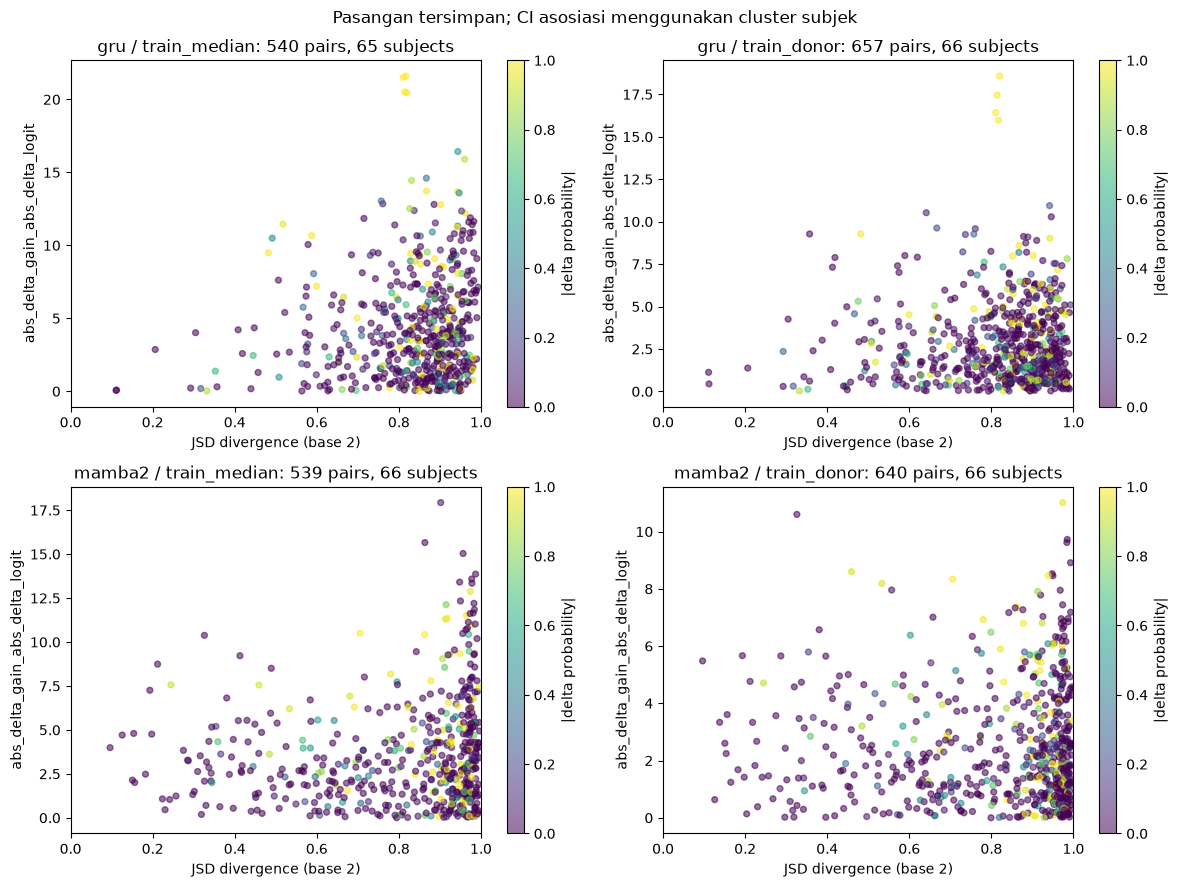

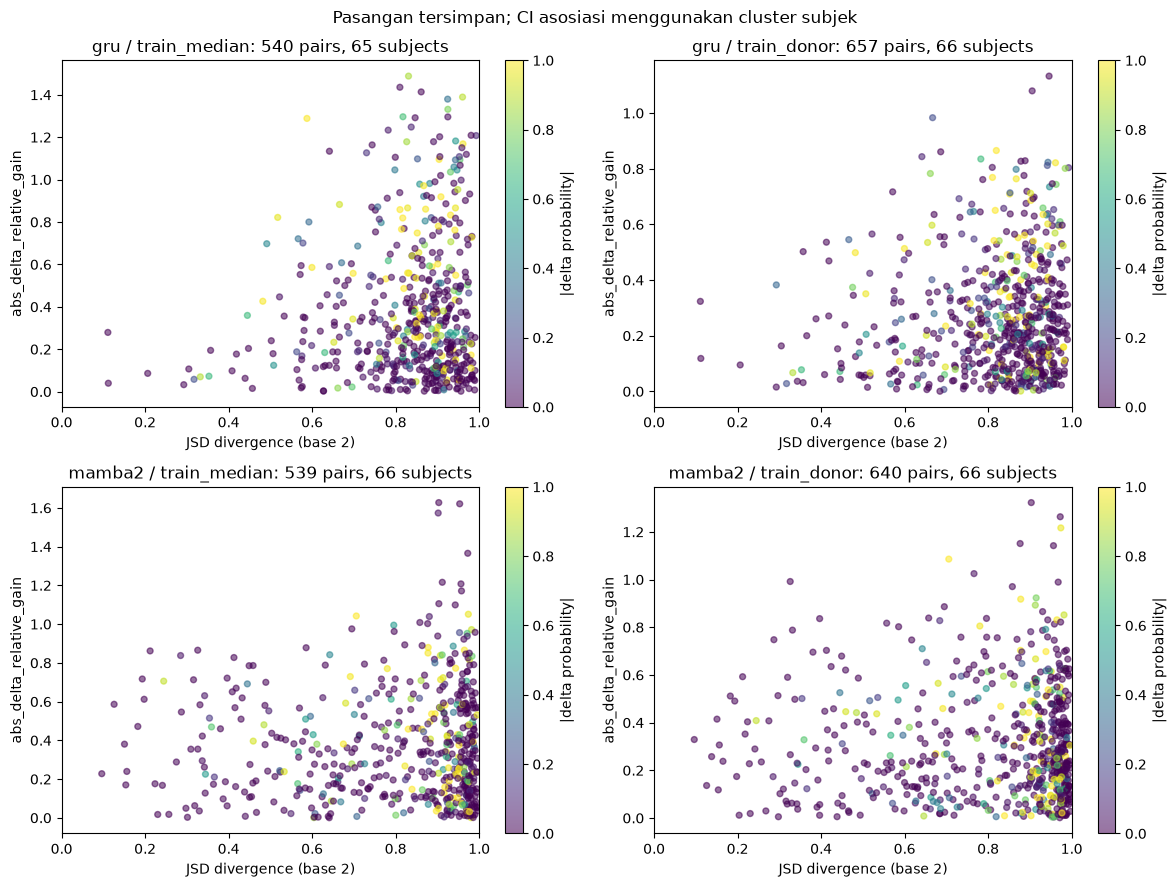

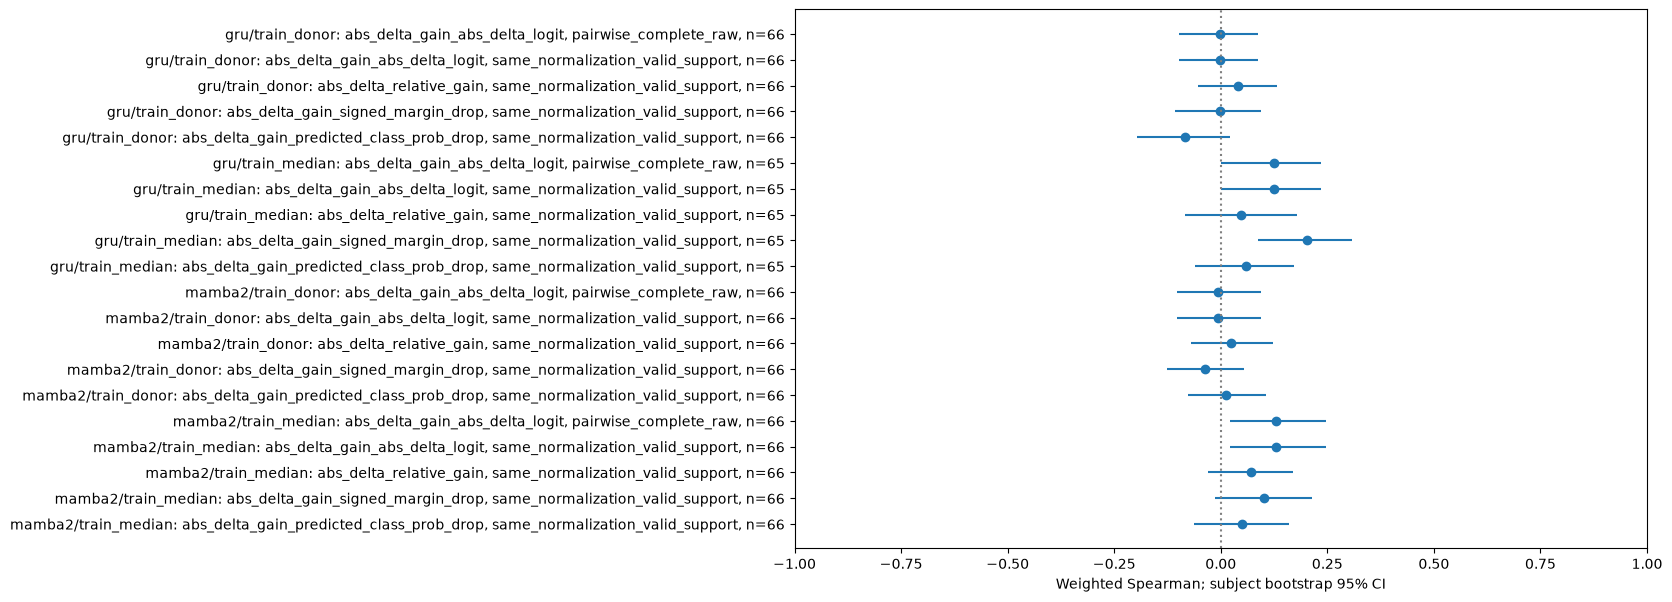

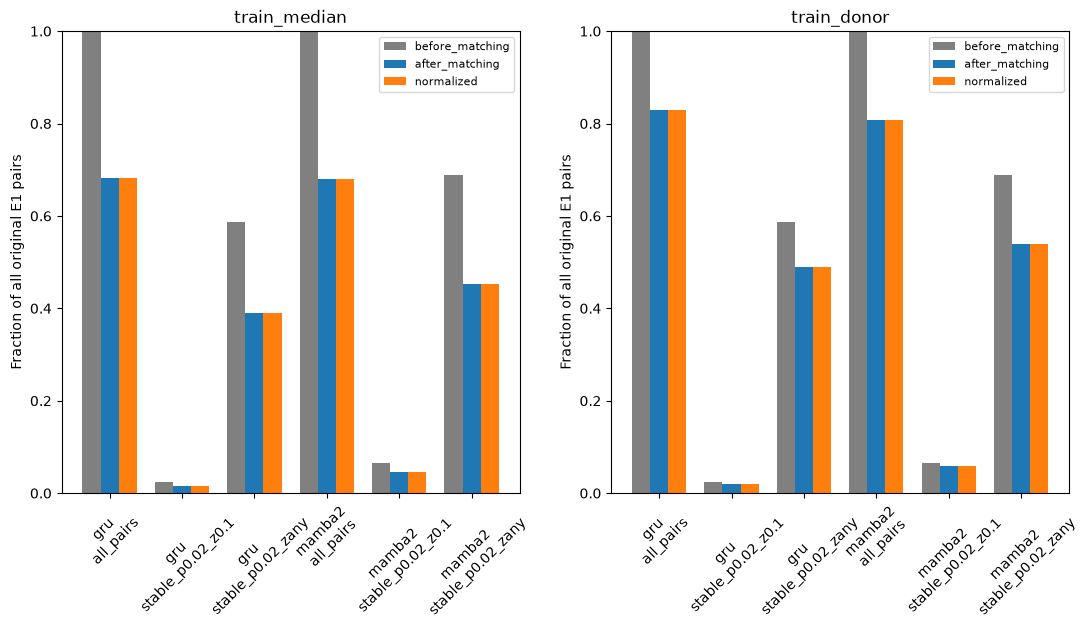

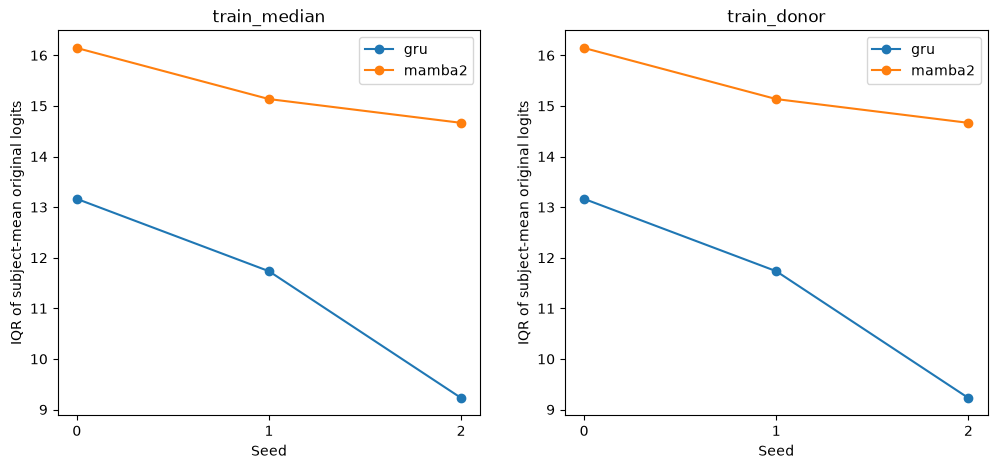

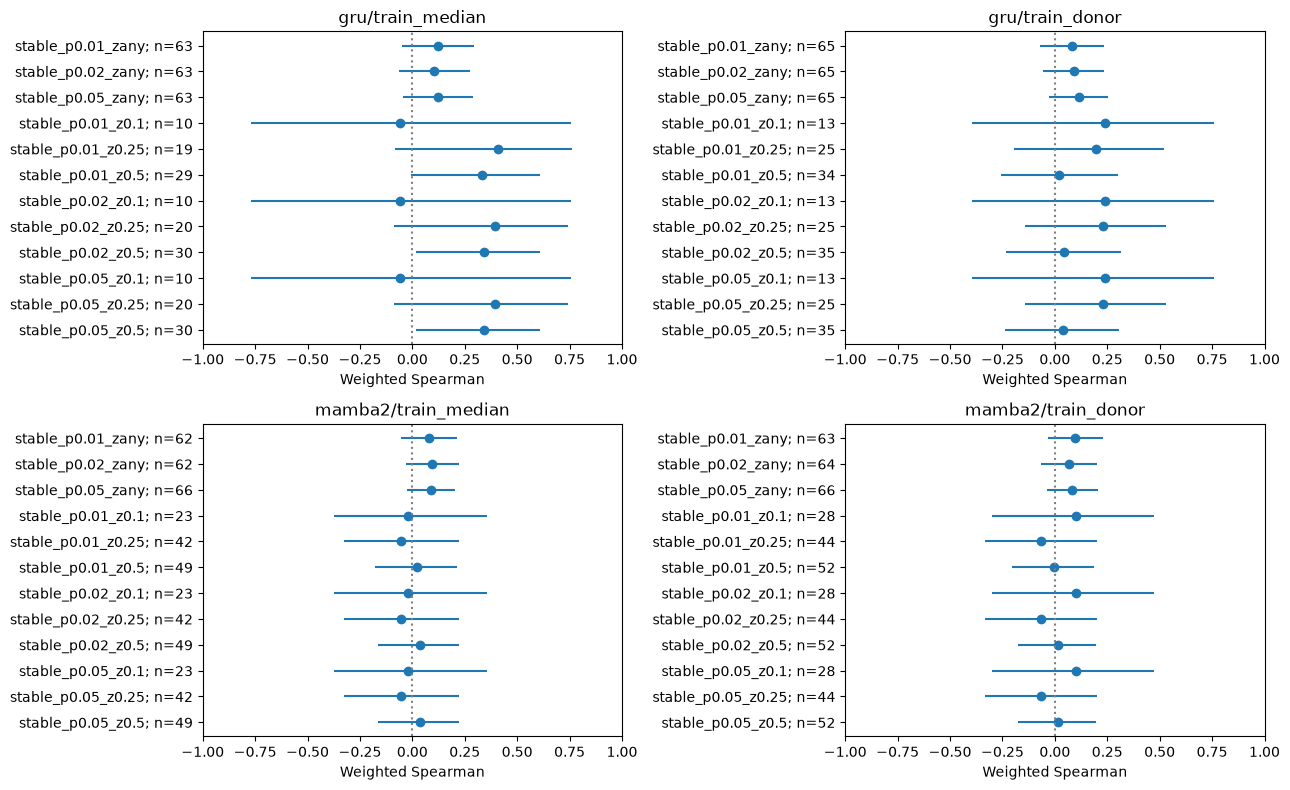

In [8]:
logit_rows = []
for (mid,idx),p in maps.items():
    rec,spec = records.iloc[idx],specs[mid]
    logit_rows.append(dict(architecture=spec['architecture'],seed=int(spec['seed']),fold=int(spec['fold']),
                          model_id=mid,idx=idx,subject=rec.subject,label=int(rec.label),logit=float(p['logit']),
                          abs_logit=abs(float(p['logit']))))
unmasked = pd.DataFrame(logit_rows)
scale_subject = unmasked.groupby(['architecture','seed','subject','label'])[['logit','abs_logit']].mean().reset_index()
effect_subject = contrasts.groupby(['architecture','masker','seed','subject','label'])[
    ['aopc_top_abs_delta_logit','aopc_rms_abs_delta_logit','paired_rms_abs_delta_logit','matched_curve_complete']].mean().reset_index()
matched_top = contrasts.loc[contrasts.matched_curve_complete].groupby(
    ['architecture','masker','seed','subject','label']).aopc_top_abs_delta_logit.mean().rename('top_matched').reset_index()
effect_subject = effect_subject.merge(matched_top,on=['architecture','masker','seed','subject','label'],
                                     how='left',validate='one_to_one')
scale_effects = scale_subject.merge(effect_subject,on=['architecture','seed','subject','label'],validate='one_to_many')
scale_effects.to_csv(OUT/'logit_scale_subject.csv',index=False)
scale_rows = []
for (arm,masker,seed),group in scale_effects.groupby(['architecture','masker','seed'],sort=True):
    q25,q75 = np.quantile(group.logit,[.25,.75])
    scale_rows.append(dict(architecture=arm,masker=masker,seed=int(seed),n_subjects=len(group),
        subject_logit_q25=q25,subject_logit_q75=q75,subject_logit_iqr=q75-q25,
        subject_abs_logit_median=float(group.abs_logit.median()),
        top_mean_full=float(group.aopc_top_abs_delta_logit.mean()),
        top_mean_matched=float(group.top_matched.mean()),
        rms_mean_conditional=float(group.aopc_rms_abs_delta_logit.mean()),
        gain_mean_conditional=float(group.paired_rms_abs_delta_logit.mean()),
        n_subjects_with_matched_effect=int(group.top_matched.notna().sum()),
        mean_record_matching_fraction=float(group.matched_curve_complete.mean())))
pd.DataFrame(scale_rows).to_csv(OUT/'logit_scale_diagnostics.csv',index=False)

def save_figure(fig,name):
    fig.savefig(FIG/(name+'.png'),dpi=180,bbox_inches='tight')
    fig.savefig(FIG/(name+'.pdf'),bbox_inches='tight')
    plt.show()
    plt.close(fig)

for outcome,tag in [('abs_delta_gain_abs_delta_logit','raw'),('abs_delta_relative_gain','normalized')]:
    fig,axes = plt.subplots(len(ARMS),len(MASKERS),figsize=(12,9),squeeze=False)
    for i,arm in enumerate(ARMS):
        for j,masker in enumerate(MASKERS):
            g = pairs[(pairs.architecture==arm)&(pairs.masker==masker)&pairs.pair_eligible]
            if tag=='normalized':
                g = g[g.normalization_eligible]
            ax = axes[i,j]
            sc = ax.scatter(g.js_divergence,g[outcome],c=g.abs_delta_prob,vmin=0,vmax=1,
                            cmap='viridis',s=18,alpha=.55,rasterized=True)
            ax.set(xlim=(0,1),xlabel='JSD divergence (base 2)',ylabel=outcome,
                   title=f'{arm} / {masker}: {len(g)} pairs, {g.subject.nunique()} subjects')
            fig.colorbar(sc,ax=ax,label='|delta probability|')
    fig.suptitle('Pasangan tersimpan; CI asosiasi menggunakan cluster subjek')
    fig.tight_layout()
    save_figure(fig,'map_vs_gain_'+tag)

primary_plot = associations[(associations.scenario=='all_pairs')
    &(associations.level_id=='aopc_all_budgets')&(associations.x=='js_divergence')
    &(associations.estimator=='subject_balanced_weighted_spearman')
    &((associations.support=='pairwise_complete_raw')|(associations.support=='same_normalization_valid_support'))]
fig,ax = plt.subplots(figsize=(11,7))
for i,row in enumerate(primary_plot.itertuples(index=False)):
    if np.isfinite(row.estimate):
        ax.plot(row.estimate,i,'o',color='tab:blue')
    if np.isfinite(row.ci_low) and np.isfinite(row.ci_high):
        ax.hlines(i,row.ci_low,row.ci_high,color='tab:blue')
labels = [f'{r.architecture}/{r.masker}: {r.y}, {r.support}, n={r.n_subjects}' for r in primary_plot.itertuples(index=False)]
ax.set(yticks=range(len(labels)),yticklabels=labels,xlim=(-1,1),xlabel='Weighted Spearman; subject bootstrap 95% CI')
ax.axvline(0,color='grey',linestyle=':')
ax.invert_yaxis()
save_figure(fig,'association_forest')

fig,axes = plt.subplots(1,len(MASKERS),figsize=(13,6),squeeze=False)
for j,masker in enumerate(MASKERS):
    ax = axes[0,j]
    rows = coverage[(coverage.masker==masker)&(coverage.level_id=='aopc_all_budgets')
                    &coverage.scenario.isin(['all_pairs','stable_p0.02_zany','stable_p0.02_z0.1'])]
    labels = [f'{r.architecture}\n{r.scenario}' for r in rows.itertuples(index=False)]
    x = np.arange(len(rows))
    for offset,stage,color in [(-.25,'before_matching','grey'),(0,'after_matching','tab:blue'),(.25,'normalized','tab:orange')]:
        ax.bar(x+offset,rows['fraction_pairs_'+stage],width=.25,label=stage,color=color)
    ax.set(xticks=x,xticklabels=labels,ylim=(0,1),ylabel='Fraction of all original E1 pairs',title=masker)
    ax.tick_params(axis='x',rotation=45)
    ax.legend(fontsize=8)
save_figure(fig,'matching_and_stability_coverage')

fig,axes = plt.subplots(1,len(MASKERS),figsize=(12,5),squeeze=False)
scale_df = pd.DataFrame(scale_rows)
for j,masker in enumerate(MASKERS):
    for arm in ARMS:
        g = scale_df[(scale_df.architecture==arm)&(scale_df.masker==masker)].sort_values('seed')
        axes[0,j].plot(g.seed,g.subject_logit_iqr,'o-',label=arm)
    axes[0,j].set(xlabel='Seed',ylabel='IQR of subject-mean original logits',title=masker,xticks=SEEDS)
    axes[0,j].legend()
save_figure(fig,'original_logit_scale')

fig,axes = plt.subplots(len(ARMS),len(MASKERS),figsize=(13,8),squeeze=False)
for i,arm in enumerate(ARMS):
    for j,masker in enumerate(MASKERS):
        subset = associations[(associations.architecture==arm)&(associations.masker==masker)
             &(associations.level_id=='aopc_all_budgets')&(associations.support=='same_normalization_valid_support')
             &(associations.estimator=='subject_balanced_weighted_spearman')&(associations.x=='js_divergence')
             &(associations.y=='abs_delta_relative_gain')&associations.scenario.str.startswith('stable_')]
        ax = axes[i,j]
        for k,row in enumerate(subset.itertuples(index=False)):
            if np.isfinite(row.estimate):
                ax.plot(row.estimate,k,'o',color='tab:blue')
            if np.isfinite(row.ci_low):
                ax.hlines(k,row.ci_low,row.ci_high,color='tab:blue')
        ax.set(xlim=(-1,1),yticks=range(len(subset)),
               yticklabels=[f'{r.scenario}; n={r.n_subjects}' for r in subset.itertuples(index=False)],
               xlabel='Weighted Spearman',title=arm+'/'+masker)
        ax.axvline(0,color='grey',linestyle=':')
        ax.invert_yaxis()
fig.tight_layout()
save_figure(fig,'stable_output_sensitivity')

## Keluaran yang harus diperiksa

| Berkas | Kegunaan |
|---|---|
| `alignment_checks.csv`, `input_inventory.csv` | identitas checkpoint/rekaman/fold/seed/grid, target mask, caliper RMS/geometri/kuota, nilai E1/AOPC, SHA sebelum/sesudah |
| `rms_background_support.csv` | background RMS berhasil yang tersimpan, termasuk pada titik parsial yang tetap dikecualikan dari agregasi |
| `bridge_pairs_aopc.csv`, `bridge_pairs_budget.csv` | seluruh pasangan termasuk yang gagal matching, alasan exclusion, G/H kedua seed, perubahan bertanda dan absolut |
| `coverage.csv`, `coverage_subject.csv`, `coverage_seed_pairs.csv`, `coverage_by_class.csv`, `coverage_ci.csv` | penyusutan pasangan, rekaman, subjek, dan kelas; denominasi awal vs conditional |
| `association_ci.csv` | kontinu primer raw, raw/norm pada support sama, centering subjek, stable-output, floor, budget, dan sensitivitas metrik peta |
| `subject_summaries.csv`, `subject_mean_ci.csv` | pasangan → rekaman → subjek; ukuran perubahan peta/output/relevansi dan CI |
| `logit_scale_subject.csv`, `logit_scale_diagnostics.csv` | skala logit asli dan besarnya efek tiap seed, tanpa fitting atau kalibrasi |
| `scale_contrast_ci.csv` | selisih asosiasi normalized−raw pada support sama, dengan draw subjek berpasangan |
| `subject_bootstrap_counts.npz` | draw cluster yang sama untuk semua estimand; subject IDs anonim penelitian |
| `analysis_manifest.json` | identitas baru, exploratory, sumber/definisi/config, batas inferensi, tidak ada training/intervensi |
| Grafik PNG + PDF | scatter raw/norm, forest association CI, cakupan matching/stabilitas, skala logit, sensitivitas stable-output |

Urutan membaca: **alignment → coverage → skala/support normalized → asosiasi
kontinu → dalam-subjek → stable-output/budget**. Jangan mendahulukan subset
yang CI-nya paling menarik. Pool bootstrap berisi semua subjek awal, termasuk
yang tidak memiliki pasangan eligible. `coverage.csv` menyajikan kelas gabungan;
`coverage_by_class.csv` dan `coverage_subject.csv` menyimpan breakdown HC/PD.

- Asosiasi positif: perubahan peta menyertai perubahan keuntungan relatif
  ranking **dalam pengujian dan support ini**; belum berarti kualitas menurun.
- Asosiasi lemah/CI mencakup nol: hubungan belum ditetapkan; bukan kesetaraan
  atau bukti bahwa perubahan peta tidak penting.
- Raw dan H berbeda: telaah sensitivitas skala dan denominator, bukan memilih
  salah satu berdasarkan arah hasil. H mengabaikan besar efek absolut.
  Selisih rho pada `scale_contrast_ci.csv` mengukur sensitivitas terhadap ukuran
  outcome; bukan estimasi kausal efek skala logit yang terisolasi.
- Peta berubah dengan G/H serupa: konsisten dengan variasi ranking yang
  menghasilkan nilai evaluasi serupa; satu skor tidak membuktikan explanation
  ekuivalen atau faithful secara keseluruhan.
- Sensitivitas per-budget `used_top_mask_disagreement` memakai patch-set
  top-k yang benar-benar diintervensi E2, dengan tie-break seed lama; berbeda
  dari Jaccard fractional E1 pada top 10%. Respons model antar-seed sendiri
  juga dapat berubah walaupun patch-set identik.
- Masker/model berbeda: laporkan tiap strata. Tidak menggabungkan logit raw
  lintas arsitektur untuk menetapkan arsitektur yang lebih faithful.

Rencana perturbasi input E3 tetap belum dijalankan oleh notebook ini. Hasil
bridge akan dipakai bersama E2 untuk menilai perlunya tindak lanjut, tanpa
mengubah status preregistrasi lama.

In [9]:
check(source_digest(NOTEBOOK)==SOURCE_DIGEST,'bridge notebook scientific source unchanged')
inventory_rows = []
for path,before in sorted(tracked.items(),key=lambda item:str(item[0])):
    after = file_hash(path)
    inventory_rows.append(dict(path=str(path.relative_to(ROOT)),sha256_before=before,
                               sha256_after=after,unchanged=before==after))
inventory_output = pd.DataFrame(inventory_rows)
inventory_output.to_csv(OUT/'input_inventory.csv',index=False)
check(inventory_output.unchanged.all(),'all source artifacts unchanged after analysis')
pd.DataFrame(checks).to_csv(OUT/'alignment_checks.csv',index=False)
spec = dict(analysis_kind=ANALYSIS_KIND,design_date=DESIGN_DATE,analysis_status='additional_exploratory',
    baseline_run=BASELINE.name,amplitude_run=AMPLITUDE.name,baseline_evaluation_id=EXPECTED_EVALUATION,
    amplitude_control_id=EXPECTED_CONTROL,source_notebook_sha256=SOURCE_DIGEST,
    input_hashes=dict(zip(inventory_output.path,inventory_output.sha256_before)),
    pair_support='both seeds complete; full curve for primary; per-budget for sensitivity; third seed not required',
    primary=dict(x='base-2 JSD divergence',y='abs(G_b-G_a)',gain='G=T-RMS',estimator='subject-balanced weighted Spearman'),
    scale_sensitivity=dict(relative_gain='H=(T-R)/(T+R); T,R absolute-logit AOPC',floors=list(DENOM_FLOORS),
                          comparison='raw and normalized on identical normalized-valid pair support'),
    bootstrap=dict(unit='subject',strata='HC/PD',n_boot=N_BOOT,seed=BOOT_SEED,confidence=CONFIDENCE,
                   interval='percentile',min_eligible_subjects=MIN_CI_SUBJECTS,min_valid_draw_fraction=.95,
                   shared_draws=True,weights='equal subject -> equal eligible record -> equal eligible seed pair'),
    stable_sensitivity=[dict(name=n,eps_prob=p,eps_logit=z,same_class=s) for n,p,z,s in SCENARIOS],
    inference='conditional on saved checkpoints/splits/three seeds/libraries/controls/matching; no new training or interventions',
    claim='association of map change with operational ranking relevance change; no automatic decline/faithfulness/causal claim')
manifest = dict(run_id=RUN_ID,analysis_id=digest(spec),analysis_spec=spec,completion_status='complete',
    analysis_status='additional_exploratory_after_E1_E2_RMS_results_known',analysis_design_date=DESIGN_DATE,
    old_preregistration_changed=False,training_performed=False,model_inference_performed=False,
    new_interventions_performed=False,original_E3_input_perturbation_plan_executed=False,
    scientific_source=str(NOTEBOOK.relative_to(ROOT)),notebook_source_sha256=SOURCE_DIGEST,
    versions={name:version(name) for name in ('numpy','pandas','scipy','matplotlib')},python=platform.python_version(),
    completed_utc=datetime.now(timezone.utc).isoformat(),
    tables=sorted(p.name for p in OUT.glob('*.csv')),figures=sorted(p.name for p in FIG.glob('*')))
(OUT/'analysis_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Complete:',OUT)
print('Analisis tambahan eksploratori; input/artifact/baseline tetap; E3 perturbasi input belum dijalankan.')

Complete: /home/agribychaniago/Python Projects/Skripsi/results/e1_e2_rms_bridge/20261014T041914953496Z
Analisis tambahan eksploratori; input/artifact/baseline tetap; E3 perturbasi input belum dijalankan.
